# Combining adversarial training with temporal structure

This native Julia companion preserves the public observations, chronological boundary, model architecture, objectives, fixed training schedule and diagnostic definitions. Julia TimeGAN initialization, training and sampling use local `MersenneTwister` streams with the displayed integer seeds; other demonstrations use `Xoshiro`. Their realizations differ from NumPy and PyTorch. The diagnostic logistic solver uses tighter convergence for the same fixed objective. Native arrays, model weights and training draws are saved as CSV/TOML under `outputs/julia/artifacts` for independent verification. Run these three notebooks in order. Figures use the requested dark theme.

The original adversarial game compares observed data with samples produced from random inputs:

$$
\min_G\max_D V(D,G)
=\mathbb E_{X\sim p_{\mathrm{data}}}[\log D(X)]
+\mathbb E_{Z\sim p_Z}[\log(1-D(G(Z)))].
$$

Here, $G$ is the generator; $D(x)$ is the discriminator's assigned probability that $x$ came from the observed distribution; $X\sim p_{\mathrm{data}}$ is an observed sample; $Z\sim p_Z$ is a random input; $G(Z)$ is a generated sample. The discriminator maximizes the expression, while the generator minimizes it.

## Training latent sequences with three losses

The temporal model first maps an observed window $X$ into a latent sequence and then maps it back:

$$
H=E(X),
\qquad
\widetilde X=R(H),
\qquad
\widehat H=G(Z),
\qquad
\widehat X=R(\widehat H).
$$

Here, $E$ is the embedding map; $R$ is the recovery map; $H$ is the latent representation of an observed window; $G$ is an autoregressive generator; $Z$ is a sequence of independent Gaussian inputs; $\widehat H$ is a generated latent sequence; $\widetilde X$ is a reconstruction; $\widehat X$ is a generated feature window.

For a batch of $B$ windows, the reconstruction loss is

$$
L_R=\frac{1}{B}\sum_{i=1}^{B}\sum_{t=1}^{T}\lVert X_{i,t}-\widetilde X_{i,t}\rVert_2^2.
$$

Here, $i$ identifies a window; $t$ identifies a position within the window; $T$ is the window length; $\lVert\cdot\rVert_2$ is Euclidean length. The loss measures how much information is lost when a window is embedded and recovered.

The supervised temporal loss is

$$
L_S=\frac{1}{B}\sum_{i=1}^{B}\sum_{t=1}^{T}\lVert H_{i,t}-G_t(H_{i,1:t-1},Z_{i,t})\rVert_2^2.
$$

Here, $G_t(H_{i,1:t-1},Z_{i,t})$ is the latent vector produced at position $t$ when the generator receives the preceding observed latent history and the current random input. The loss compares the generated next latent vector with the latent vector obtained from the observed sequence.

The adversarial value for temporal latent vectors is

$$
L_U=\frac{1}{B}\sum_{i=1}^{B}\sum_{t=1}^{T}\left[\log D(H_{i,t})+\log\left(1-D(\widehat H_{i,t})\right)\right].
$$

Here, $D(H_{i,t})$ and $D(\widehat H_{i,t})$ are the discriminator probabilities assigned to observed and generated latent vectors. The discriminator seeks a large $L_U$; the minimax generator seeks a small term for generated data.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("03_generative_financial_time_series");
using CSV, TOML
artifacts = joinpath(book_root(), "outputs", "julia", "artifacts", "03_generative_financial_time_series")
mkpath(artifacts)

function save_tensor(name, values)
    CSV.write(joinpath(artifacts, name*".csv"), DataFrame(Value=vec(values)))
    open(joinpath(artifacts, name*".toml"), "w") do stream
        TOML.print(stream, Dict("shape"=>collect(size(values)), "storage_order"=>"column-major"))
    end
    return nothing
end

function load_tensor(name)
    shape = TOML.parsefile(joinpath(artifacts, name*".toml"))["shape"]
    values = CSV.read(joinpath(artifacts, name*".csv"), DataFrame).Value
    return reshape(Float64.(values), Tuple(shape))
end

pack_parameters(values::NamedTuple) = Dict(string(key)=>pack_parameters(getproperty(values, key)) for key in keys(values))
pack_parameters(values::AbstractArray) = Dict("shape"=>collect(size(values)), "values"=>vec(values))

function unpack_parameters(template::NamedTuple, saved)
    return NamedTuple{keys(template)}(Tuple(unpack_parameters(getproperty(template, key), saved[string(key)]) for key in keys(template)))
end

function unpack_parameters(template::AbstractArray, saved)
    @assert Tuple(saved["shape"]) == size(template)
    return reshape(Float64.(saved["values"]), size(template))
end

function save_parameters(name, parameters)
    open(joinpath(artifacts, name*".toml"), "w") do stream
        TOML.print(stream, pack_parameters(parameters))
    end
    return nothing
end
prepared_metadata = TOML.parsefile(joinpath(artifacts, "prepared_metadata.toml"))
training_windows = load_tensor("training_windows")
validation_windows = load_tensor("validation_windows")
minimum_values = prepared_metadata["minimum"]
scale = prepared_metadata["scale"]
feature_names = prepared_metadata["feature_names"]
window_length = prepared_metadata["window_length"]
@assert size(training_windows) == (6409, 20, 2)


In [2]:
objective_model = RiskLabAI.Data.TimeGAN(2,4;seed=1)
generator = Xoshiro(42)
observed = rand(generator,3,5,2)
noise = randn(generator,3,5,4)
losses = RiskLabAI.Data.timegan_losses(objective_model,observed,noise)
latent = RiskLabAI.Data._timegan_sequence_map(objective_model.parameters.embedding,observed)
reconstructed = RiskLabAI.Data._timegan_sequence_map(objective_model.parameters.recovery,latent)
synthetic_latent = RiskLabAI.Data.latent_sequence(objective_model,noise)
teacher_latent = RiskLabAI.Data.latent_sequence(objective_model,noise;teacher=latent)
real_logits = RiskLabAI.Data._timegan_sequence_map(objective_model.parameters.discriminator,latent;sigmoid=false)
fake_logits = RiskLabAI.Data._timegan_sequence_map(objective_model.parameters.discriminator,synthetic_latent;sigmoid=false)
softplus(value) = max(value,0)+log1p(exp(-abs(value)))
independent = (reconstruction=sum(abs2,observed.-reconstructed)/3,supervised=sum(abs2,latent.-teacher_latent)/3,discriminator=(sum(softplus.(-real_logits))+sum(softplus.(fake_logits)))/3,generator_adversarial=-sum(softplus.(fake_logits))/3)
objective_labels = ["Reconstruction loss","Supervised temporal loss","Discriminator loss","Generator adversarial loss"]
objective_rows = NamedTuple[]
for (index,name) in enumerate(keys(independent))
    library_value, independent_value = getproperty(losses,name),getproperty(independent,name)
    @assert isapprox(library_value,independent_value;rtol=1e-10,atol=1e-12)
    push!(objective_rows,(;objective=objective_labels[index],library_value,independent_value,absolute_difference=abs(library_value-independent_value)))
end
gradient = only(RiskLabAI.Data.Zygote.gradient(parameters->sum(values(RiskLabAI.Data._timegan_losses(parameters,observed,noise))),objective_model.parameters))
@assert RiskLabAI.Data._timegan_allfinite(gradient)
changed_noise = copy(noise)
changed_noise[:,4:end,:] .+= 100
@assert RiskLabAI.Data.latent_sequence(objective_model,noise)[:,1:3,:] == RiskLabAI.Data.latent_sequence(objective_model,changed_noise)[:,1:3,:]
objective_table = DataFrame(objective_rows)
rename!(objective_table,["Objective","RiskLabAI value","Independent value","Absolute difference"])
save_data(objective_table,paths,"objective_check_values")
save_table(objective_table,paths,"objective_checks";caption="Independent calculations of the four implemented losses.",label="tab:chapter4-objective-checks")
save_parameters("objective_parameters",objective_model.parameters)
save_tensor("objective_observed",observed)
save_tensor("objective_noise",noise)


Row,Objective,RiskLabAI value,Independent value,Absolute difference
,String,Float64,Float64,Float64
1,Reconstruction loss,1.12091,1.12091,0.0
2,Supervised temporal loss,0.586778,0.586778,0.0
3,Discriminator loss,6.93315,6.93315,8.88178e-16
4,Generator adversarial loss,-3.24842,-3.24842,0.0


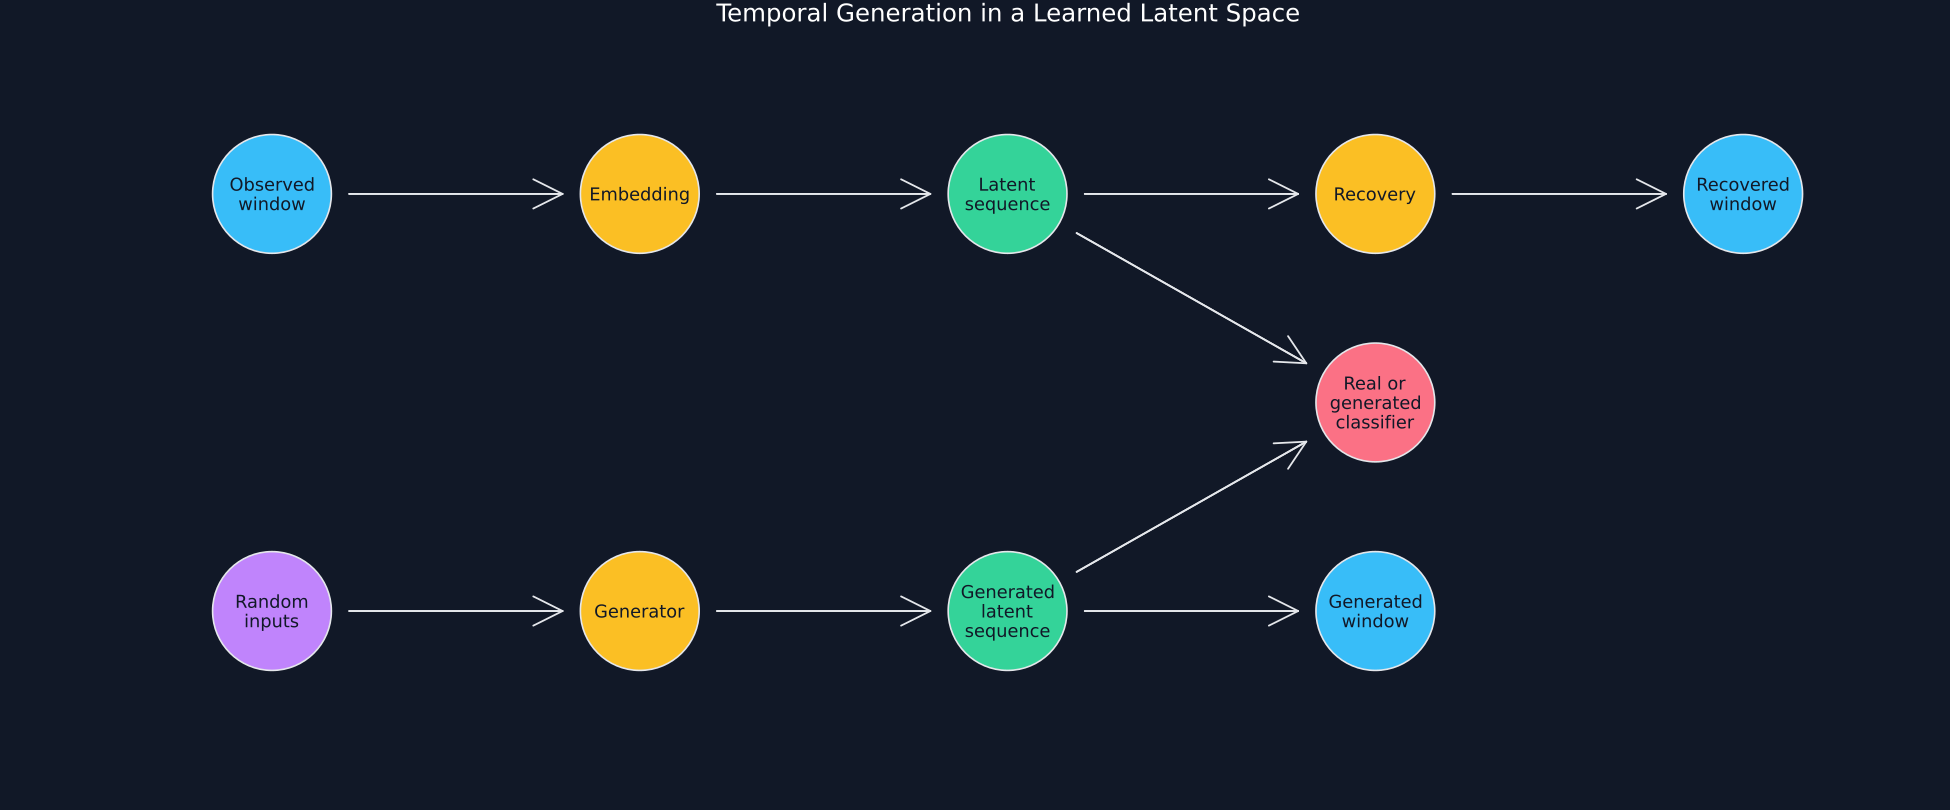

In [3]:
nodes = DataFrame("Component"=>["Observed window","Embedding","Latent sequence","Recovery","Reconstruction","Random inputs","Generator","Generated latent sequence","Generated window","Discriminator"],"X"=>[0,2,4,6,8,0,2,4,6,6],"Y"=>[2,2,2,2,2,0,0,0,0,1],"Group"=>["data","map","latent","map","data","noise","map","latent","data","judge"])
edges = DataFrame("Source"=>["Observed window","Embedding","Latent sequence","Recovery","Random inputs","Generator","Generated latent sequence","Generated latent sequence","Latent sequence"],"Target"=>["Embedding","Latent sequence","Recovery","Reconstruction","Generator","Generated latent sequence","Generated window","Discriminator","Discriminator"])
save_data(nodes,paths,"component_nodes")
save_data(edges,paths,"component_edges")
positions = Dict(row.Component=>(row.X,row.Y) for row in eachrow(nodes))
colors = Dict("data"=>palette.cyan,"map"=>palette.amber,"latent"=>palette.green,"noise"=>"#C084FC","judge"=>palette.rose)
labels = ["Observed
window","Embedding","Latent
sequence","Recovery","Recovered
window","Random
inputs","Generator","Generated
latent
sequence","Generated
window","Real or
generated
classifier"]
diagram = plot(;xlims=(-.9,8.9),ylims=(-.65,2.65),axis=false,grid=false,legend=false,title="Temporal Generation in a Learned Latent Space",size=(1300,540))
for row in eachrow(edges)
    start,stop = positions[row.Source],positions[row.Target]
    dx,dy = stop[1]-start[1],stop[2]-start[2]
    distance = sqrt(dx^2+dy^2)
    inset = min(.42,.3distance)
    plot!(diagram,[start[1]+inset*dx/distance,stop[1]-inset*dx/distance],[start[2]+inset*dy/distance,stop[2]-inset*dy/distance];color=palette.text,linewidth=1.2,arrow=true,label=false)
end
for (index,row) in enumerate(eachrow(nodes))
    scatter!(diagram,[row.X],[row.Y];markersize=44,color=colors[row.Group],markerstrokecolor=palette.text,label=false)
    annotate!(diagram,row.X,row.Y,text(labels[index],8,palette.background,:center))
end
save_figure(diagram,paths,"timegan_component_map")


## Three Training Phases

The embedding and recovery parameters solve

$$
\min_{\theta_E,\theta_R}\left(L_R+\lambda L_S\right),
$$

while the generator parameters solve

$$
\min_{\theta_G}\left(L_{G,\mathrm{adv}}+\eta L_S\right),
$$

and the discriminator parameters solve

$$
\min_{\theta_D}(-L_U).
$$

Here, $\theta_E$, $\theta_R$, $\theta_G$, and $\theta_D$ are the adjustable parameters of the embedding, recovery, generator, and discriminator maps. $L_{G,\mathrm{adv}}$ is the term for generated data in the adversarial value; $\lambda\geq0$ weights supervised temporal learning in the embedding step; $\eta\geq0$ weights it in the generator step. The first phase trains reconstruction, the second trains supervised temporal generation, and the third combines all objectives.

In [4]:
settings = (embedding_steps=20,supervised_steps=20,joint_steps=40,batch_size=64,learning_rate=.001,embedding_weight=1.,generator_weight=10.,seed=4105)
model = RiskLabAI.Data.TimeGAN(2,8;seed=4104)
save_parameters("timegan_initial_parameters",model.parameters)
training_generator = MersenneTwister(4105)
training_draws = [(indices=rand(training_generator,1:size(training_windows,1),64),noise=randn(training_generator,64,20,8)) for _ in 1:80]
CSV.write(joinpath(artifacts,"training_indices.csv"),DataFrame(hcat(getproperty.(training_draws,:indices)...),:auto))
CSV.write(joinpath(artifacts,"training_noise.csv"),DataFrame(hcat(vec.(getproperty.(training_draws,:noise))...),:auto))
history = RiskLabAI.Data.fit_timegan(model,training_windows;settings...,training_draws)
@assert length(history) == 80
@assert getproperty.(history,:phase) == vcat(fill("embedding",20),fill("supervised",20),fill("joint",40))
@assert all(isfinite(getproperty(entry,name)) for entry in history for name in (:reconstruction,:supervised,:discriminator,:generator_adversarial))
history_frame = DataFrame(history)
rename!(history_frame,["Phase","Reconstruction loss","Supervised temporal loss","Discriminator loss","Generator adversarial loss"])
insertcols!(history_frame,1,"Step"=>collect(1:80))
history_frame.Phase = uppercasefirst.(history_frame.Phase)
save_data(history_frame,paths,"training_history")
save_parameters("timegan_parameters",model.parameters)
open(joinpath(artifacts,"timegan_settings.toml"),"w") do stream
    TOML.print(stream,merge(Dict("features"=>2,"hidden_size"=>8,"model_seed"=>4104),Dict(string(key)=>getproperty(settings,key) for key in keys(settings))))
end
settings_table = DataFrame("Setting"=>["Feature count","Window length","Hidden units","Embedding steps","Supervised steps","Joint steps","Batch size","Learning rate","Embedding supervised weight","Generator supervised weight","Model seed","Training seed"],"Value"=>[2,20,8,20,20,40,64,.001,1,10,4104,4105])
save_table(settings_table,paths,"timegan_settings";caption="Fixed settings chosen before the training run with public data.",label="tab:chapter4-timegan-settings")
phase_rows = NamedTuple[]
for phase in ["Embedding","Supervised","Joint"]
    part = history_frame[history_frame.Phase.==phase,:]
    push!(phase_rows,(;phase,steps=nrow(part),first_reconstruction=part[1,"Reconstruction loss"],last_reconstruction=part[end,"Reconstruction loss"],first_supervised=part[1,"Supervised temporal loss"],last_supervised=part[end,"Supervised temporal loss"]))
end
phase_summary = DataFrame(phase_rows)
rename!(phase_summary,["Phase","Steps","First reconstruction loss","Last reconstruction loss","First supervised loss","Last supervised loss"])
save_table(phase_summary,paths,"training_phase_summary";caption="Loss values at the beginning and end of each fixed training phase.",label="tab:chapter4-training-phases")


Row,Setting,Value
,String,Float64
1,Feature count,2.0
2,Window length,20.0
3,Hidden units,8.0
4,Embedding steps,20.0
5,Supervised steps,20.0
6,Joint steps,40.0
7,Batch size,64.0
8,Learning rate,0.001
9,Embedding supervised weight,1.0


Row,Phase,Steps,First reconstruction loss,Last reconstruction loss,First supervised loss,Last supervised loss
,String,Int64,Float64,Float64,Float64,Float64
1,Embedding,20,2.72459,2.101,1.02254,1.22796
2,Supervised,20,2.12354,1.90807,1.23459,0.875014
3,Joint,40,1.92047,0.991976,0.844052,0.139177


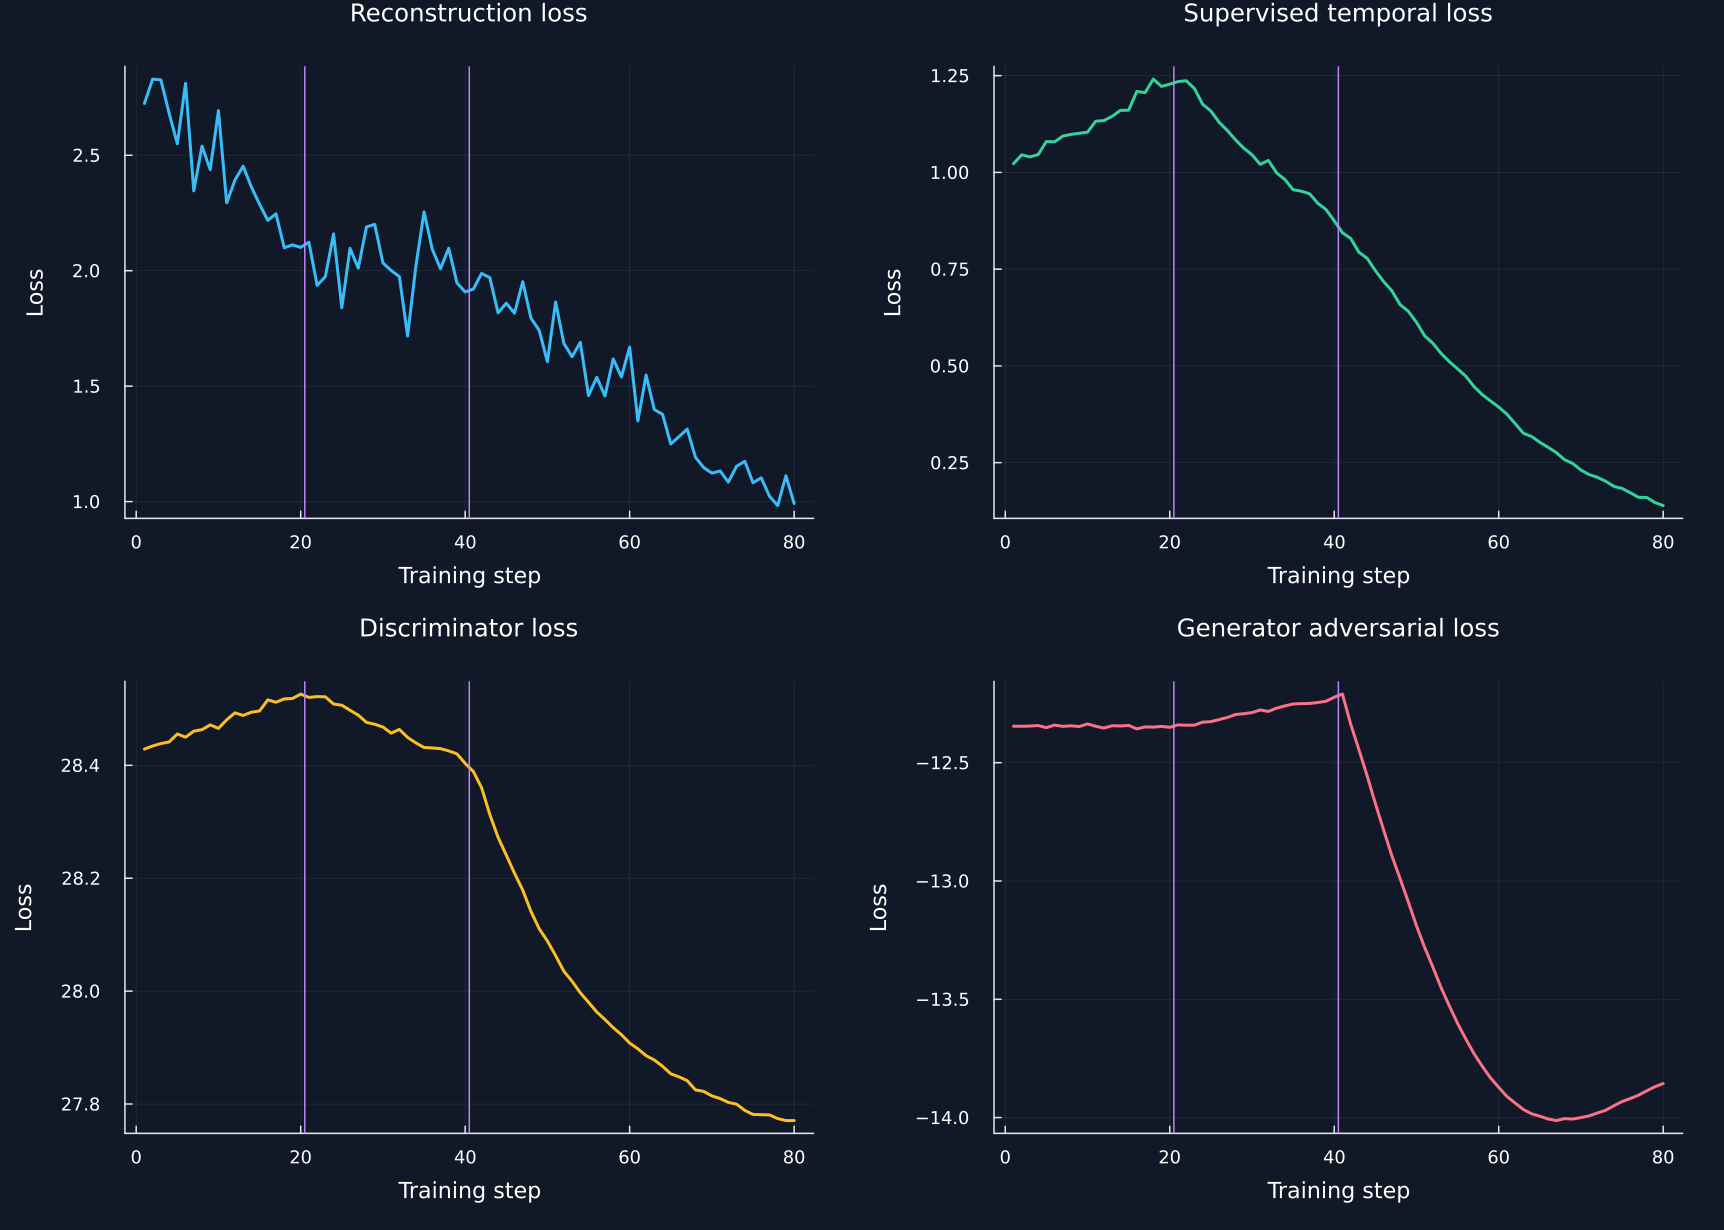

In [5]:
loss_columns = ["Reconstruction loss","Supervised temporal loss","Discriminator loss","Generator adversarial loss"]
loss_colors = [palette.cyan,palette.green,palette.amber,palette.rose]
panels = []
for (column,color) in zip(loss_columns,loss_colors)
    panel = plot(history_frame.Step,history_frame[!,column];color,title=column,xlabel="Training step",ylabel="Loss",label=false)
    vline!(panel,[20.5,40.5];color="#C084FC",linewidth=1,label=false)
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(2,2),size=(1150,820)),paths,"training_losses")


Row,Source,Feature,Mean,Standard deviation,Minimum,Maximum
,String,String,Float64,Float64,Float64,Float64
1,Observed training window,Daily log return (%),0.111678,0.603073,-1.01246,1.36607
2,Observed training window,Twenty-day return volatility (%),0.791604,0.0566513,0.603073,0.845175
3,Reconstruction,Daily log return (%),-0.968119,0.0449389,-0.998051,-0.783746
4,Reconstruction,Twenty-day return volatility (%),2.02637,0.124409,1.95736,2.41286
5,Generated window,Daily log return (%),-0.961684,0.0371853,-1.00096,-0.828308
6,Generated window,Twenty-day return volatility (%),2.02443,0.122114,1.95284,2.40506


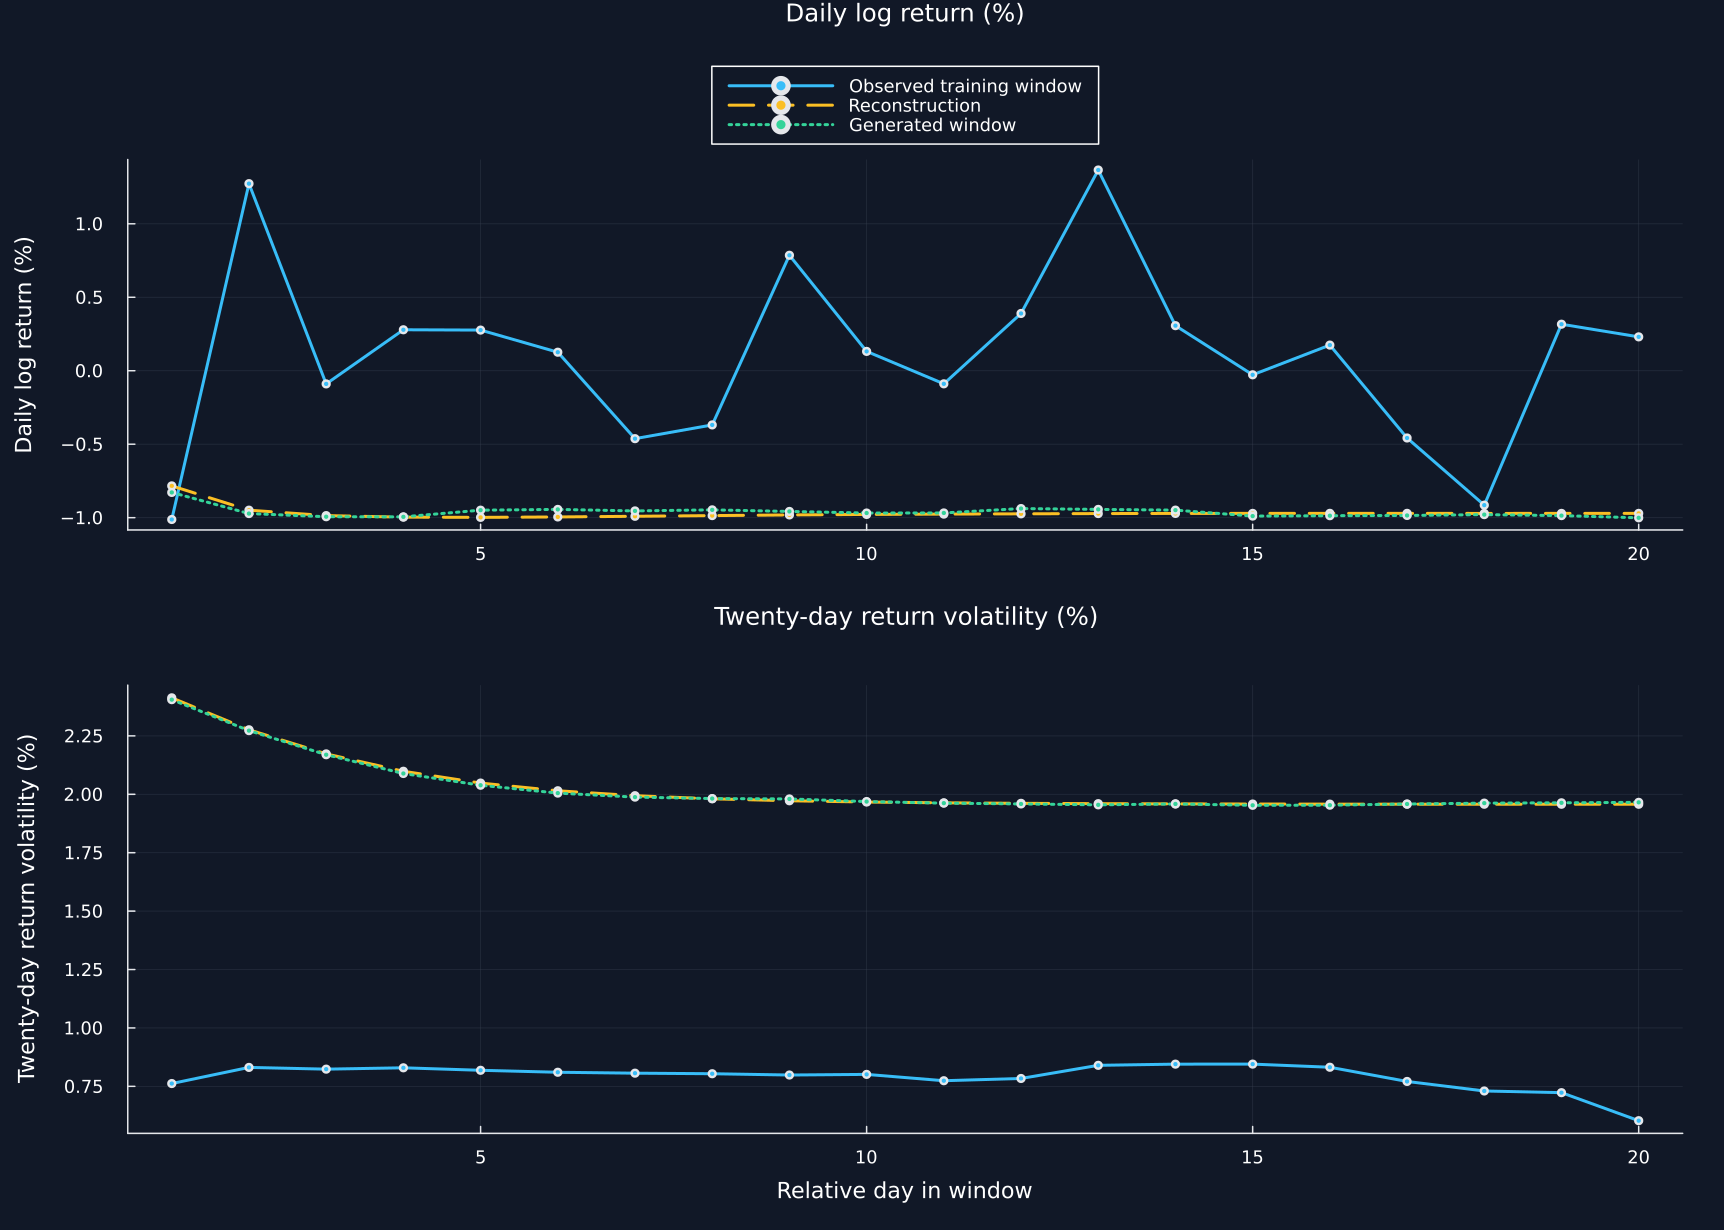

In [6]:
selected_scaled = training_windows[101:101,:,:]
selected_latent = RiskLabAI.Data._timegan_sequence_map(model.parameters.embedding,selected_scaled)
reconstructed_scaled = RiskLabAI.Data._timegan_sequence_map(model.parameters.recovery,selected_latent)[1,:,:]
generated_scaled = RiskLabAI.Data.sample_timegan(model,1,window_length;seed=4108)[1,:,:]
real_window = training_windows[101,:,:].*scale'.+minimum_values'
reconstructed_window = reconstructed_scaled.*scale'.+minimum_values'
generated_window = generated_scaled.*scale'.+minimum_values'
window_rows = NamedTuple[]
for (source,values) in [("Observed training window",real_window),("Reconstruction",reconstructed_window),("Generated window",generated_window)], day in 1:window_length, (j,feature) in enumerate(feature_names)
    push!(window_rows,(;source,day,feature,value=values[day,j]))
end
window_examples = DataFrame(window_rows)
rename!(window_examples,["Source","Relative day","Feature","Value"])
save_data(window_examples,paths,"model_window_examples")
summary_rows = NamedTuple[]
for part in groupby(window_examples,[:Source,:Feature];sort=false)
    push!(summary_rows,(;source=part.Source[1],feature=part.Feature[1],average=mean(part.Value),deviation=std(part.Value),minimum=minimum(part.Value),maximum=maximum(part.Value)))
end
window_summary = DataFrame(summary_rows)
rename!(window_summary,["Source","Feature","Mean","Standard deviation","Minimum","Maximum"])
save_table(window_summary,paths,"model_window_summary";caption="Summary of one fixed observed window, its reconstruction, and one generated window.",label="tab:chapter4-model-window-summary")
panels = []
for (index,feature) in enumerate(feature_names)
    panel = plot(;xlabel=index==2 ? "Relative day in window" : "",ylabel=feature,title=feature,legend=:outertop)
    for (source,color,style) in [("Observed training window",palette.cyan,:solid),("Reconstruction",palette.amber,:dash),("Generated window",palette.green,:dot)]
        part = window_examples[(window_examples.Source.==source).&(window_examples.Feature.==feature),:]
        plot!(panel,part[!,"Relative day"],part.Value;color,linestyle=style,marker=:circle,markersize=2.5,label=index==1 ? source : false)
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(2,1),size=(1150,820)),paths,"reconstruction_generated_windows")


## Tests

In [7]:
before = rand(copy(Random.default_rng()),3)
tiny = RiskLabAI.Data.TimeGAN(1,4;seed=8)
@assert before == rand(copy(Random.default_rng()),3)
toy_series = reshape(sin.((0:99)./4),:,1)
toy_data = RiskLabAI.Data.chronological_timegan_data(toy_series;training_end=60,window_length=6)
toy_settings = (embedding_steps=2,supervised_steps=2,joint_steps=2,batch_size=5,seed=12)
toy_history = RiskLabAI.Data.fit_timegan(tiny,toy_data.training;toy_settings...)
twin = RiskLabAI.Data.TimeGAN(1,4;seed=8)
@assert RiskLabAI.Data.fit_timegan(twin,toy_data.training;toy_settings...) == toy_history
@assert getproperty.(toy_history,:phase) == ["embedding","embedding","supervised","supervised","joint","joint"]
@assert RiskLabAI.Data.sample_timegan(tiny,20,6;seed=10) == RiskLabAI.Data.sample_timegan(twin,20,6;seed=10)
training_checks = DataFrame("Check"=>["Independent loss calculations","Finite gradients","Future noise leaves earlier outputs unchanged","Three phases in fixed order","Repeated seeds reproduce training","Repeated seeds reproduce samples","Public-data losses finite"],"Result"=>fill("Pass",7))
save_table(training_checks,paths,"training_checks";caption="Checks for objectives, gradients, temporal order, phases, and deterministic seeds.",label="tab:chapter4-training-checks")


Row,Check,Result
,String,String
1,Independent loss calculations,Pass
2,Finite gradients,Pass
3,Future noise leaves earlier outputs unchanged,Pass
4,Three phases in fixed order,Pass
5,Repeated seeds reproduce training,Pass
6,Repeated seeds reproduce samples,Pass
7,Public-data losses finite,Pass
